# Dar_020 — Environmental profiles for illustrative connected components

**Objective:** environmental evidence for choosing a lunar base location together with terrain. This follows the original notebooks 31–32 diagnostic/comparison/interpretation flow, without changing their code, CNN artifacts or protected reserves.

## Questions and prior evidence

- Q09: What environmental distributions describe the three largest illustrative components per region?
- Q10: How different are candidate slope medians, upper quantiles and extrema?
- Q11: How do shadow class and sky-view context vary within these components?
- Q12: What terrain source support, elevation-error and effective-resolution context is present?
- Q13: Which component examples have no point-associated thermal observations?
- Q14: How do temperatures compare on the same 17 common phase products?
- Q15: What phase-average variation is observed at repeatedly sampled centers?
- Q16: How do available and complete-common cohorts change candidate thermal summaries?

Read the accepted Dar_017/018 results before interpreting these extensions. The questions are related diagnostics, not independent experiments.

## Input contract and declared considerations

Use the three largest four-connected components under the predeclared 60 m, unshifted (0.5,0.5,10 degree) illustration, not a search for the best threshold. These are purposive examples, not independent/random candidate samples. Associate temperature centers only; a 240 m thermal observation is not contained by a 60 m lookup. Keep all 17 common products, absent groups and fixed-common sensitivity. No empty thermal group is replaced by zero.

In [1]:
from pathlib import Path
import sys,json
from itertools import product
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT / "env_algo_task/EDA/shared"), str(ROOT / "env_algo_task/EDA/Moon/Stage3_Requirements"),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input
from environmental_selection_eda import *
import environmental_selection_eda as methods
DATA=ROOT/'env_algo_task/data'
REGION_LIMIT=None  # Set 1 for the initial representative sample, None for all seven.
JOINT_RUN_ID='20261106T134155791814Z_c6f9ab'
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment',JOINT_RUN_ID)
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=125,bbox_inches='tight');display(fig);plt.close(fig)
def register_methods(run):
    run.input(Path(methods.__file__))
    for name in ['moon_p1_analysis.py','site_comparison.py','decision_eda.py']:
        run.input(ROOT/'env_algo_task/EDA'/name)
    for name in ['31_vertical_scale_sensitivity.ipynb','32_candidate_coverage_and_ranking.ipynb']:
        run.input(ROOT/'notebooks/modeling/terrain_similarity'/name)
def publish(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8')
    display(record)
def selected_regions(values):
    regions=sorted(values)
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region sample')
        regions=regions[:REGION_LIMIT]
    return regions

Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab


In [2]:
SPATIAL_RUN_ID=None  # Set an accepted run ID for exact reproduction.

## Build a new local run and compare the data

Inputs and helper source hashes are recorded. Results remain under `env_algo_task/data/processed/analysis/`; source downloads and earlier notebooks are not overwritten.

Accepted local analysis/dar_019_spatial_environment run: 20261107T160008649706Z_ef39d7
Accepted local analysis/dar_002_temperature_environment run: 20261106T082929336242Z_623f9f
Accepted local analysis/dar_017_lunar_site_profiles run: 20261106T163555259282Z_731d59


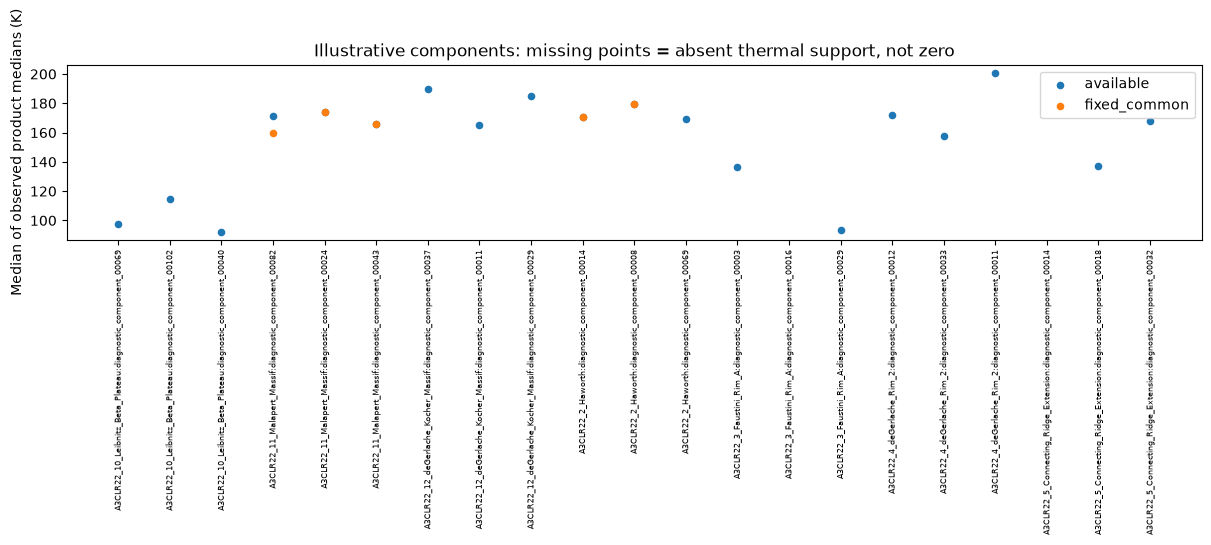

,region,candidate_id,usable_center_product_rows,distinct_associated_centers,common_products_observed,expected_common_products,association
0,A3CLR22_10_Leibnitz_Beta_Plateau,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,191,12,16,17,center only; 240 m thermal support is not cont...
1,A3CLR22_10_Leibnitz_Beta_Plateau,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,15,1,15,17,center only; 240 m thermal support is not cont...
2,A3CLR22_10_Leibnitz_Beta_Plateau,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,32,2,16,17,center only; 240 m thermal support is not cont...
3,A3CLR22_11_Malapert_Massif,A3CLR22_11_Malapert_Massif:diagnostic_componen...,196,12,17,17,center only; 240 m thermal support is not cont...
4,A3CLR22_11_Malapert_Massif,A3CLR22_11_Malapert_Massif:diagnostic_componen...,187,11,17,17,center only; 240 m thermal support is not cont...
5,A3CLR22_11_Malapert_Massif,A3CLR22_11_Malapert_Massif:diagnostic_componen...,68,4,17,17,center only; 240 m thermal support is not cont...
6,A3CLR22_12_deGerlache_Kocher_Massif,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,30,3,10,17,center only; 240 m thermal support is not cont...
7,A3CLR22_12_deGerlache_Kocher_Massif,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,14,1,14,17,center only; 240 m thermal support is not cont...
8,A3CLR22_12_deGerlache_Kocher_Massif,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,30,3,10,17,center only; 240 m thermal support is not cont...
9,A3CLR22_2_Haworth,A3CLR22_2_Haworth:diagnostic_component_00014,68,4,17,17,center only; 240 m thermal support is not cont...


,candidate_id,cohort,supported_products,minimum_centers_per_product,median_of_product_medians_K,minimum_product_median_K,maximum_product_median_K,span_of_product_medians_K
0,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,available,16,0,91.897640,67.693371,220.518143,152.824772
1,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,fixed_common,0,0,NaN,NaN,NaN,NaN
2,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,available,16,0,97.899895,61.676414,216.213684,154.537270
3,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,fixed_common,0,0,NaN,NaN,NaN,NaN
4,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,available,15,0,114.327316,55.727650,182.531631,126.803981
5,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,fixed_common,0,0,NaN,NaN,NaN,NaN
6,A3CLR22_11_Malapert_Massif:diagnostic_componen...,available,17,11,173.961929,69.575676,246.704788,177.129112
7,A3CLR22_11_Malapert_Massif:diagnostic_componen...,fixed_common,17,11,173.961929,69.575676,246.704788,177.129112
8,A3CLR22_11_Malapert_Massif:diagnostic_componen...,available,17,4,165.865478,67.003153,237.080543,170.077390
9,A3CLR22_11_Malapert_Massif:diagnostic_componen...,fixed_common,17,4,165.865478,67.003153,237.080543,170.077390


**Observed influence:** 5 of 21 illustrative components have some point-associated observation in every common product. This does not establish fixed-center or full-footprint coverage; missing thermal groups cannot support a hard thermal pass.

{'questions': ['Q09', 'Q10', 'Q11', 'Q12', 'Q13', 'Q14', 'Q15', 'Q16'],
 'regions': 7,
 'candidate_examples': 21,
 'candidates_without_point_associated_thermal': 2,
 'candidates_with_all_common_products': 5,
 'associated_distinct_regional_centers': 73,
 'associated_centers_with_all_products': 25,
 'thermal_profile_rows': 714,
 'limits': ['Examples are selected by diagnostic component size, not overall suitability',
  'Point association does not prove full thermal-footprint containment',
  'Phase-average spans are not mission extrema or heating rates']}

In [3]:
spatial=latest_completed_run(ROOT,'analysis/dar_019_spatial_environment',SPATIAL_RUN_ID)
environment=latest_completed_run(ROOT,'analysis/dar_002_temperature_environment','20261106T082929336242Z_623f9f')
profile=latest_completed_run(ROOT,'analysis/dar_017_lunar_site_profiles','20261106T163555259282Z_731d59')
with Run(ROOT,'analysis/dar_020_candidate_environment',{'region_limit':REGION_LIMIT,'spatial_run':str(spatial.relative_to(ROOT)),
    'thermal_environment_run':str(environment.relative_to(ROOT)),'association':'point-containing 60 m diagnostic cell; not full thermal footprint',
    'candidate_selection':'size-ordered examples, not independent best-base samples'},'Moon/Site_Assessment/Dar_020_candidate_environment_profiles.ipynb') as run:
    register_methods(run)
    manifest=pd.read_csv(accepted_input(run,spatial,'diagnostic_candidate_manifest.csv'))
    metas=json.loads(accepted_input(run,spatial,'grid_metadata.json').read_text())
    products=json.loads(accepted_input(run,profile,'comparison_contract.json').read_text())['common_products']
    regions=selected_regions(metas);manifest=manifest.loc[manifest.region.isin(regions)]
    if manifest.empty:raise ValueError('No illustrative candidate components; keep the no-match spatial report instead')
    static=[];phases=[];spans=[];association=[]
    for region in regions:
        cells=pd.read_csv(accepted_input(run,spatial,'grids/'+region+'.csv.gz'),dtype={'candidate_id':'string'})
        selected=manifest.loc[manifest.region.eq(region),'candidate_id'].tolist()
        static.append(candidate_static_profiles(cells))
        path=accepted_input(run,environment,'paired_observations/'+region+'.csv.gz')
        columns=['region','source_product','clon','clat','x_m','y_m','tbol','usable','complete_common_cohort']
        pieces=[]
        for chunk in pd.read_csv(path,usecols=columns,chunksize=200_000):
            if not chunk.region.eq(region).all():raise ValueError('Wrong paired source region')
            chosen=chunk.loc[chunk.source_product.isin(products)].copy()
            chosen['candidate_id']=associate_points(chosen,cells,metas[region])
            pieces.append(chosen)
        observations=pd.concat(pieces,ignore_index=True)
        phases.append(candidate_thermal_profiles(observations,selected,products))
        spans.append(center_phase_spans(observations,products))
        for candidate in selected:
            part=observations.loc[observations.candidate_id.eq(candidate)&observations.usable]
            association.append({'region':region,'candidate_id':candidate,'usable_center_product_rows':len(part),
                'distinct_associated_centers':len(part[['clon','clat']].drop_duplicates()),
                'common_products_observed':part.source_product.nunique(),'expected_common_products':len(products),
                'association':'center only; 240 m thermal support is not contained by a 60 m point lookup'})
    static=pd.concat(static,ignore_index=True);phase=pd.concat(phases,ignore_index=True);span=pd.concat(spans,ignore_index=True)
    association=pd.DataFrame(association)
    phase_summary=phase.groupby(['candidate_id','cohort']).agg(supported_products=('usable_centers',lambda x:x.gt(0).sum()),
        minimum_centers_per_product=('usable_centers','min'),median_of_product_medians_K=('tbol_median_K','median'),
        minimum_product_median_K=('tbol_median_K','min'),maximum_product_median_K=('tbol_median_K','max')).reset_index()
    phase_summary['span_of_product_medians_K']=phase_summary.maximum_product_median_K-phase_summary.minimum_product_median_K
    phase_summary.loc[phase_summary.supported_products.lt(2),'span_of_product_medians_K']=np.nan
    wide=static.pivot(index='candidate_id',columns='variable',values='median')
    terrain_q90=static.loc[static.variable.eq('slope_deg')].set_index('candidate_id').q90
    pool=manifest[['candidate_id','region','nominal_projected_area_m2']].rename(columns={'candidate_id':'unit_id'})
    pool['pool']='illustrative_connected_components'
    pool=pool.merge(wide[['solar_visibility','earth_visibility']],left_on='unit_id',right_index=True,validate='one_to_one')
    pool=pool.rename(columns={'solar_visibility':'solar_fraction','earth_visibility':'earth_fraction'})
    pool['slope_deg']=pool.unit_id.map(terrain_q90)
    static.to_csv(run.path('candidate_static_profiles.csv'),index=False)
    phase.to_csv(run.path('candidate_common_product_thermal.csv'),index=False)
    phase_summary.to_csv(run.path('candidate_thermal_summary.csv'),index=False)
    cohort_compare=phase_summary.loc[phase_summary.cohort.eq('available')].merge(
        phase_summary.loc[phase_summary.cohort.eq('fixed_common')],on='candidate_id',suffixes=('_available','_fixed'),validate='one_to_one')
    cohort_compare['fixed_minus_available_median_K']=cohort_compare.median_of_product_medians_K_fixed-cohort_compare.median_of_product_medians_K_available
    cohort_compare.to_csv(run.path('candidate_thermal_cohort_comparison.csv'),index=False)
    span.to_csv(run.path('associated_center_phase_spans.csv'),index=False)
    association.to_csv(run.path('candidate_thermal_association_support.csv'),index=False)
    pool.to_csv(run.path('connected_component_comparison_pool.csv'),index=False)
    manifest.to_csv(run.path('candidate_manifest.csv'),index=False)
    fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
    positions={candidate:i for i,candidate in enumerate(manifest.candidate_id)}
    for cohort,p in phase_summary.groupby('cohort'):
        ax.scatter(p.candidate_id.map(positions).to_numpy(dtype=float),p.median_of_product_medians_K,label=cohort,s=20)
    ax.set_xticks(range(len(manifest)),manifest.candidate_id,rotation=90,fontsize=6)
    ax.set(ylabel='Median of observed product medians (K)',
        title='Illustrative components: missing points = absent thermal support, not zero');ax.legend()
    savefig(run,fig,'candidate_thermal_support')
    display(association);display(phase_summary)
    display(Markdown('**Observed influence:** '+str(int(association.common_products_observed.eq(len(products)).sum()))+' of '+str(len(association))+' illustrative components have some point-associated observation in every common product. This does not establish fixed-center or full-footprint coverage; missing thermal groups cannot support a hard thermal pass.'))
    publish(run,{'questions':['Q%02d'%i for i in range(9,17)],'regions':len(regions),'candidate_examples':len(manifest),
        'candidates_without_point_associated_thermal':int(association.distinct_associated_centers.eq(0).sum()),
        'candidates_with_all_common_products':int(association.common_products_observed.eq(len(products)).sum()),
        'associated_distinct_regional_centers':len(span),'associated_centers_with_all_products':int(span.all_common_products_observed.sum()),
        'thermal_profile_rows':len(phase),'limits':['Examples are selected by diagnostic component size, not overall suitability',
        'Point association does not prove full thermal-footprint containment','Phase-average spans are not mission extrema or heating rates']})
OUT=run.directory

## Findings and observed influence

Read the executed `findings.json`, tables and plots above; counts and missing groups are part of the result. An observed rank/availability change is sensitivity under the declared controls, not evidence that the changed setting is correct.

## Effect on hard rules and soft preferences

Profiles are evidence for criterion design, not a hardware response or full-footprint guarantee. Temperature direction and allowable slopes require actual specifications. Keep shadow, sky view and terrain-quality context even when they do not become soft scores.

## Implementation handoff and next decision

Reuse the functions in `../../shared/environmental_selection_eda.py` and retain source/assessment-unit contracts. Compare available evidence before adopting any rule. See [EDA scope and findings](../../EDA_Notes.md#scope-and-coverage), [EDA results](../../EDA_Notes.md) and [the proposal](../../../Brief_Overview.md#algorithm-proposal) for the full EDA → influence → proposed implementation chain. Exact CNN-patch matching remains optional; local, regional and reference evidence must not be conflated.

## Save reusable data and disposable reports

The completed run above already saved reusable tables, plots, `findings.json` and provenance together. Later notebooks read accepted table exports rather than notebook display outputs. Clear/regenerate disposable reports only if intended; no source data were deleted.